<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_4_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_4_Logistic_Regression.ipynb)

# MAT 422 - Section 3.4: Logistic Regression

**Topics:** Sigmoid/logistic function, Binary classification probabilities, Logistic regression fitting and interpretation

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)


## Sigmoid/logistic function

We plot the logistic function from [-8, 8]:

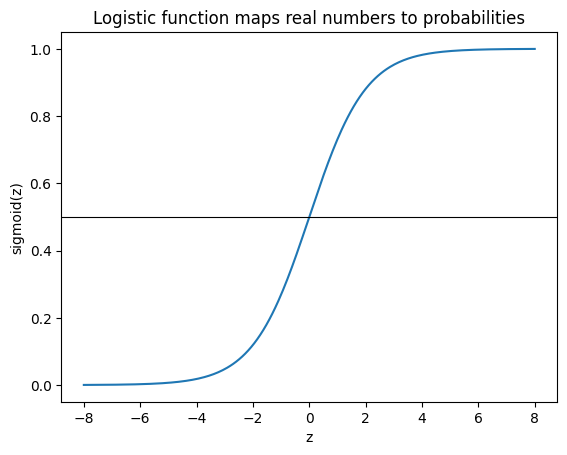

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 300)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Logistic function maps real numbers to probabilities")
plt.show()


We see the function starts near 0, goes to 0.5 near x=0, then slowly approaches (but does not touch) 1.

We then plot how w and b change sigmoid(wx+b):

sigmoid(-2), sigmoid(0), sigmoid(2) = [0.1192 0.5    0.8808]
sigmoid(-2) + sigmoid(2) = 1.0000
w = 1, b = -2: p = 0.5 at x = -b/w = 2
w = 1, b = 0: p = 0.5 at x = -b/w = 0
w = 1, b = 2: p = 0.5 at x = -b/w = -2


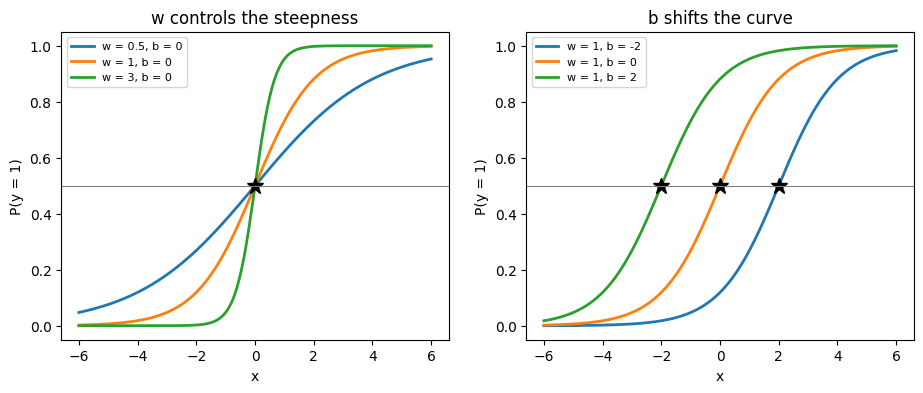

In [5]:
print("sigmoid(-2), sigmoid(0), sigmoid(2) =", sigmoid(np.array([-2, 0, 2])))
print(f"sigmoid(-2) + sigmoid(2) = {sigmoid(-2) + sigmoid(2):.4f}")

xs = np.linspace(-6, 6, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for w in [0.5, 1, 3]:
    ax[0].plot(xs, sigmoid(w * xs), lw=2, label=f"w = {w}, b = 0")
ax[0].plot(0, 0.5, "k*", ms=12)
for b in [-2, 0, 2]:
    print(f"w = 1, b = {b}: p = 0.5 at x = -b/w = {-b}")
    ax[1].plot(xs, sigmoid(xs + b), lw=2, label=f"w = 1, b = {b}")
    ax[1].plot(-b, 0.5, "k*", ms=12)
for a, title in [(ax[0], "w controls the steepness"), (ax[1], "b shifts the curve")]:
    a.axhline(0.5, color="gray", lw=0.8)
    a.set(title=title, xlabel="x", ylabel="P(y = 1)")
    a.legend(fontsize=8)
plt.show()

w changes how steep the curve is, while b shifts it left or right. -b/w is the 0.5 point.

## Binary classification probabilities

In binary classification, each example has a label 0 or 1, Logistic regression can be used to output a probability (between 0 and 1), and anything above a threshold (usually 0.5) turns into 1 and below to 0.


In [3]:
X, y = make_classification(n_samples=120, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=422)
model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))


Coefficients: [[0.9652 3.4485]]
Intercept: [2.6793]
Training accuracy: 0.975
Confusion matrix:
[[60  0]
 [ 3 57]]


sigmoid(z) matches predict_proba? True
      z        p    predicted  true
 -2.386   0.0842      0        0
  3.706   0.9760      1        1
  6.136   0.9978      1        1
 -3.975   0.0184      0        0
  4.343   0.9872      1        1
misclassified points: p = [0.4997 0.1661 0.4788]


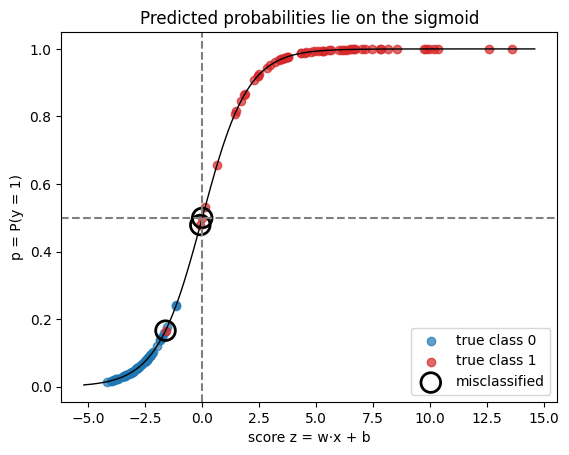

In [6]:
z_data = X @ model.coef_[0] + model.intercept_[0]
print("sigmoid(z) matches predict_proba?", np.allclose(sigmoid(z_data), proba))
print("      z        p    predicted  true")
for i in range(5):
    print(f"{z_data[i]:7.3f}   {proba[i]:.4f}      {pred[i]}        {y[i]}")
wrong = pred != y
print("misclassified points: p =", proba[wrong])

zs = np.linspace(z_data.min() - 1, z_data.max() + 1, 300)
plt.plot(zs, sigmoid(zs), "k", lw=1)
for c, color in [(0, "tab:blue"), (1, "tab:red")]:
    plt.scatter(z_data[y == c], proba[y == c], color=color, alpha=0.7, label=f"true class {c}")
plt.scatter(z_data[wrong], proba[wrong], s=200, facecolors="none", edgecolors="k", lw=2, label="misclassified")
plt.axhline(0.5, color="gray", ls="--")
plt.axvline(0, color="gray", ls="--")
plt.xlabel("score z = w·x + b")
plt.ylabel("p = P(y = 1)")
plt.title("Predicted probabilities lie on the sigmoid")
plt.legend()
plt.show()

We train the model and plot the predicted probability vs the true class (color). Two mistakes were right on the edge, while one was a fairly confident mistake. Overall, the model was quite accurate.

## Logistic regression fitting and interpretation

Logistic Regression is used because it is differentiable, allowing for gradient descent of the classifier. We fit a model and show results below:

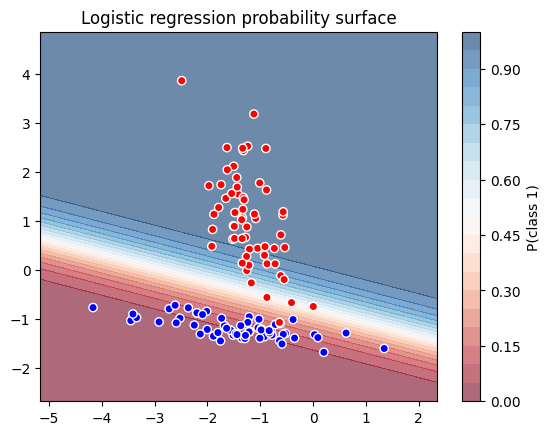

In [4]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 150),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.scatter(X[:,0], X[:,1], c=y, edgecolor="white", cmap="bwr")
plt.title("Logistic regression probability surface")
plt.show()


gradient descent: w = [0.9655 3.4459]  b = 2.677
scikit-learn:     w = [0.9652 3.4485]  b = 2.6793
loss: start = 0.6931, end = 0.1413
odds multipliers e^w = [ 2.6261 31.3706]


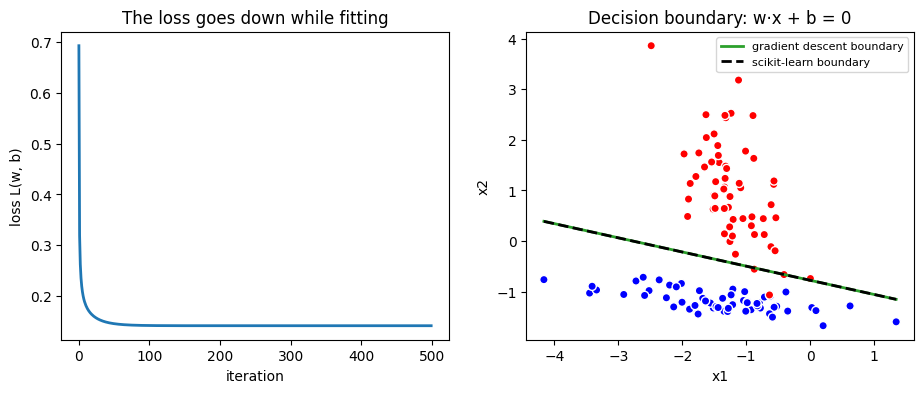

In [7]:
n = len(y)
w, b = np.zeros(2), 0.0
lr = 2.0
losses = []
for step in range(500):
    p = sigmoid(X @ w + b)
    losses.append(-np.mean(y*np.log(p) + (1 - y)*np.log(1 - p)) + w @ w / (2*n))
    w = w - lr * (X.T @ (p - y) / n + w / n)
    b = b - lr * np.mean(p - y)

print("gradient descent: w =", w, " b =", round(b, 4))
print("scikit-learn:     w =", model.coef_[0], " b =", model.intercept_[0].round(4))
print(f"loss: start = {losses[0]:.4f}, end = {losses[-1]:.4f}")
print("odds multipliers e^w =", np.exp(w))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(losses, lw=2)
ax[0].set(title="The loss goes down while fitting", xlabel="iteration", ylabel="loss L(w, b)")
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
for ww, bb, style, name in [(w, b, "C2-", "gradient descent"),
                            (model.coef_[0], model.intercept_[0], "k--", "scikit-learn")]:
    ax[1].plot(x1, -(ww[0]*x1 + bb) / ww[1], style, lw=2, label=f"{name} boundary")
ax[1].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolor="white")
ax[1].set(title="Decision boundary: w·x + b = 0", xlabel="x1", ylabel="x2")
ax[1].legend(fontsize=8)
plt.show()

The loss goes down while we fit. We can see the decision boundary and the probability surface, and can identify the confidently wrong example (the one near -0.7, -1). We observe that the data is split between two clusters and the model learns to draw a line between them..

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
